In [29]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib
import scipy.special as spl
import time
# from fle_3d import FLEBasis3D
### my modules
from fast_volume_align_ot import bh_projections, fle_3d, utils, transforms

In [43]:
M = 128
nz = 1*M
N = M//5
d = 3
sigma = 3

F = utils.generate_centered_gaussian(M, d=d, sigma=sigma)
F = transforms.translate_3d(F, 0, 0, M//4)
with open('test_volume'+str(M)+'.npy', 'wb') as f:
    np.save(f, F)

In [31]:
importlib.reload(bh_projections)

bh_projections.test_nufft(2,3)

[2.70710678+0.70710678j 1.29289322+0.70710678j 1.29289322-0.70710678j
 2.70710678-0.70710678j] [2.70710678+0.70710678j 1.29289322+0.70710678j 1.29289322-0.70710678j
 2.70710678-0.70710678j] [-1.58121871e-09+8.21597235e-11j -1.96419458e-09+3.00816150e-10j
 -2.18285079e-09-8.21597235e-11j -1.79987536e-09-3.00815928e-10j]


In [32]:
importlib.reload(bh_projections)
s1 = bh_projections.cramer(F,M,nz,N,max_l=M//2)


0.07755112648010254


/Users/oscarmi/miniconda3/envs/sw3/lib/python3.9/site-packages/finufft/_interfaces.py:336: UserWarning: Argument `data` does not satisfy the following requirement: C. Copying array (this may reduce performance)
  warnings.warn(f"Argument `{name}` does not satisfy the following requirement: {prop}. Copying array (this may reduce performance)")


In [33]:
importlib.reload(bh_projections)
s2 = bh_projections.cramer_brute_force(F,M,N,max_l=M//2)


0.11360383033752441


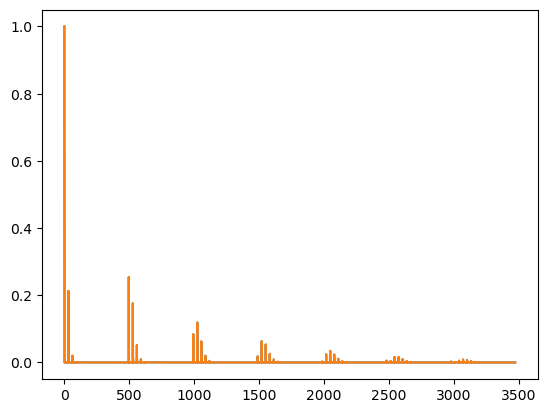

In [34]:
plt.plot(np.abs(s1).flatten()/np.max(np.abs(s1).flatten()))
plt.plot(np.abs(s2).flatten()/np.max(np.abs(s2).flatten()))

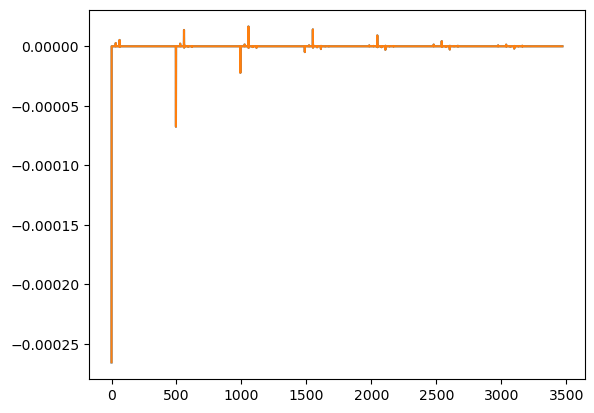

In [35]:
plt.plot(np.real(s1).flatten())
plt.plot(np.real(s2).flatten())

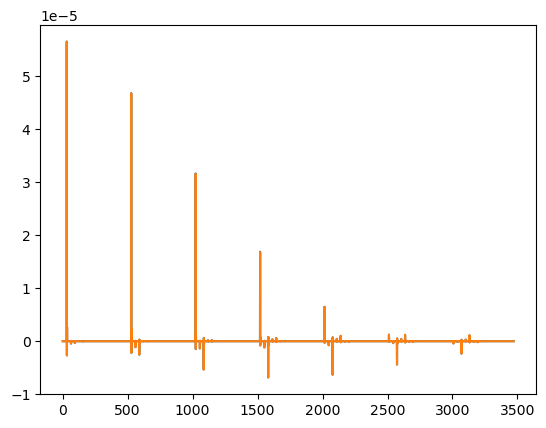

In [36]:
plt.plot(np.imag(s1).flatten())
plt.plot(np.imag(s2).flatten())

In [37]:
print(np.linalg.norm(s1), np.linalg.norm(s2),\
      np.linalg.norm(np.abs(s1-s2))/np.linalg.norm(s2),np.linalg.norm(s1)/np.linalg.norm(s2))

0.0002889791612950363 0.0002887429748001279 0.0012485730794530693 1.0008179817883773


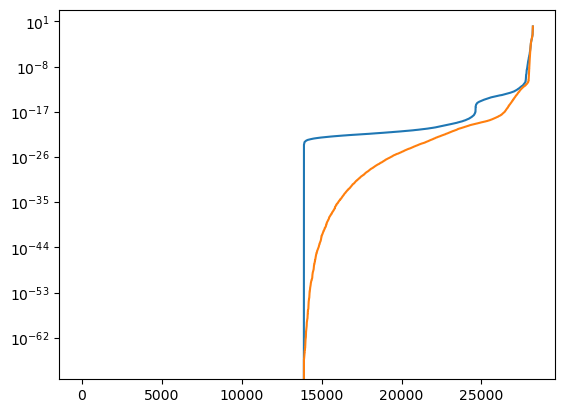

In [119]:

v1 = np.abs(s1.flatten())
v1.sort()
v2 = np.abs(s2.flatten())
v2.sort()
plt.semilogy(np.abs(v1/v1[-1]))
plt.semilogy(np.abs(v2/v2[-1]))

NameError: name 'fle' is not defined